# Fitting SDSS J0006$-$0920 with the GalSpec JAX models

This is `wrk_sagan_sdss0006.ipynb` -- the astropy/SAGAN fit of SDSS J000605.59$-$092007.0
($z = 0.0699$) -- worked through again with `galspec.jax_models`, the JAX/GPU backend. The
steps, the windows, the components, the atoms and the physics are the same; seven things are
not:

* **The engine.** Every stage here is sampled with :class:`galspec.jnesty_fit.JNesty_Fit`
  (nested sampling, GPU) instead of astropy's `LevMarLSQFitter`. Least squares returns the
  minimum of $\chi^2$; nested sampling returns the posterior, so what each stage reports is a
  median with a 68% credible interval -- the answer *and* its error -- and a model evidence.
* **Priors.** A sampler needs one per free parameter, so each stage has a prior cell. Every
  prior is scaled from the spectrum in that cell (a line peak between $10^{-2}$ and three
  times the brightest pixel, a width between a resolved line and the widest narrow line, ...),
  so the recipe transfers to another object without hand-tuning.
* **No starting values.** The constructors keep the values the SAGAN fit of this spectrum
  landed on, so the two notebooks' components read the same line by line -- but the sampler
  never starts there. It draws from the prior, and the numbers come out of the likelihood.
* **The narrow doublets are one component each.** [N II] 6548/6583, [S II] 6716/6731 and
  [O III] 4959/5007 are `Line_template_doublet`s rather than two `Line_template`s whose
  shifts are then tied, so a pair cannot drift apart and the atomic ratio is one tie. Each
  has a `single()` method, which is how one line of a pair is measured: [N II] 6583 alone for
  the BPT diagram, and the two [S II] lines separately for their ratio.
* **Plotting.** `galspec.plot.plot_fit` tests `isinstance(m, Line_MultiGauss)` against the
  *astropy* class, which a JAX leaf is not. `plot_fit_jax` is the same figure for this backend.
* **One tie fixed.** In the reference, the broad [O III] wing had `dv_c` tied to
  `amp_c0 / 2.98` -- a velocity shift tied to an amplitude ratio, evidently a typo (it drove
  the shift to 0.21 km/s). Here the 4959/5007 wing ratio is tied, and the wing's shift follows
  the narrow lines, which is what the rest of the model does.
* **The BPT axes are narrow-line ratios.** The reference divides [N II] and [O III] by the
  *broad* Balmer flux, which parks this Seyfert 1 in the "composite" region of the diagram.
  The axes are narrow-line-region diagnostics -- the broad lines come from a different gas --
  so here the denominators are the narrow Hα and Hβ, and the object lands where a 2 800 km/s
  broad Hα and [O III]/Hβ ~ 5 say it should: above the Kewley line. The broad Balmer fluxes
  are still reported, because the black-hole mass wants Hβ's width.

Two quantities turn out to be much less certain than a least-squares fit makes them look: the
split of the continuum between the stellar templates and the power law, and the amplitude and
width of the broad [O III] wing. The intervals below say so; a point estimate would not.

Run this from `example/`, where the data live. On one RTX 4090 the four stages below take about
ten minutes with the published settings (`NLIVE = 2000`, `dlogz = 0.02`); the sampler output in
this file is one such run.

**Two sampler settings, because they can quietly be wrong.** The first is `QUEUE_SIZE = 0`
below. JNesty defaults to a queue-mode sampler when `bound='multi'` (`queue_size=8`, its
Dynesty-style dynamic batch), and on these models that path is not reproducible: repeated runs
of the H$_\alpha$ stage landed on evidences between $-478$ and $-456$ with broad-line widths
differing by 40%, depending only on how much GPU memory happened to be free at the time. The
same bound in JNesty's legacy batch mode (`queue_size=0`) reproduces to half a nat, and lands
where `bound='single'` and `bound='none'` independently do, and where `dynesty` lands when the
same model is written with the astropy classes and sampled on the CPU ($-461.8 \pm 0.2$ against
JNesty's $-461.2 \pm 0.4$) -- so that is the setting used here.
The second is `NLIVE = 2000`: at 400 live points the broad-line amplitude-width ridge is
under-sampled and the evidence moves by several nats between runs even with the queue off.

The numbers below are one run at these settings. Repeating the whole notebook in a fresh
process moves the stage evidences by under a nat and the line widths by a few per cent -- inside
the intervals quoted below. That is the point of the two settings: the error bars are the
posterior's, and they do not cover a badly converged sampler.

In [1]:
%matplotlib inline

## 1. Plot the spectrum and prepare for the fitting

In [2]:
# %% setup
from pathlib import Path
import sys
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from astropy.io import fits

import matplotlib as mpl

mpl.rc("xtick", direction="in", labelsize=16)
mpl.rc("ytick", direction="in", labelsize=16)
mpl.rc("xtick.major", width=1., size=8)
mpl.rc("ytick.major", width=1., size=8)
mpl.rc("xtick.minor", width=1., size=5)
mpl.rc("ytick.minor", width=1., size=5)

HERE = Path.cwd()                        # this notebook runs from example/
sys.path.insert(0, str(HERE.parent))     # GalSpec straight from the checkout

import galspec
from galspec import jax_models as jxm
from galspec import priors
from galspec.jnesty_fit import JNesty_Fit, jax_devices_summary
from galspec.jnesty_fit_io import save_jnesty_fit_to_fits
from galspec.utils import line_wave_dict as LINE_WAVE

FLUX_LABEL = r"$F_\lambda$  [$10^{-17}$ erg s$^{-1}$ cm$^{-2}$ $\AA^{-1}$]"

In [3]:
# %% settings
# ---- what to fit, and where the answer goes -----------------------------------------
DATA_FILE = HERE / "data" / "spec-0651-52141-0434.fits"
TABLE_DIR = HERE.parent / "develop" / "temp"       # Liu+19 and Kormendy & Ho 13 tables
OUTPUT_DIR = HERE / "output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

REDSHIFT = 0.069907          # SDSS J000605.59-092007.0, from NED
A_V = 0.105                  # Galactic foreground extinction along this sight line, from NED

# 2000 live points, 2% of the evidence: the settings this file was sampled with. See the
# note on the sampler in the introduction -- both of these matter more than they look.
NLIVE, DLOGZ = 2000, 0.02
QUEUE_SIZE = 0               # 0 = JNesty's legacy batch mode; see the note in the intro
MAX_ITERATIONS = 200_000
DEVICE = "auto"              # "gpu", "cpu" or "auto"
QUICK = False                # True -> nlive 300, dlogz 0.1: a rough answer in a minute

nlive, dlogz = (300, 0.1) if QUICK else (NLIVE, DLOGZ)
print(f"device: {jax_devices_summary()}")

device: gpu:0 (19.0 GB)


Flux units: 1E-17 erg/cm^2/s/Ang


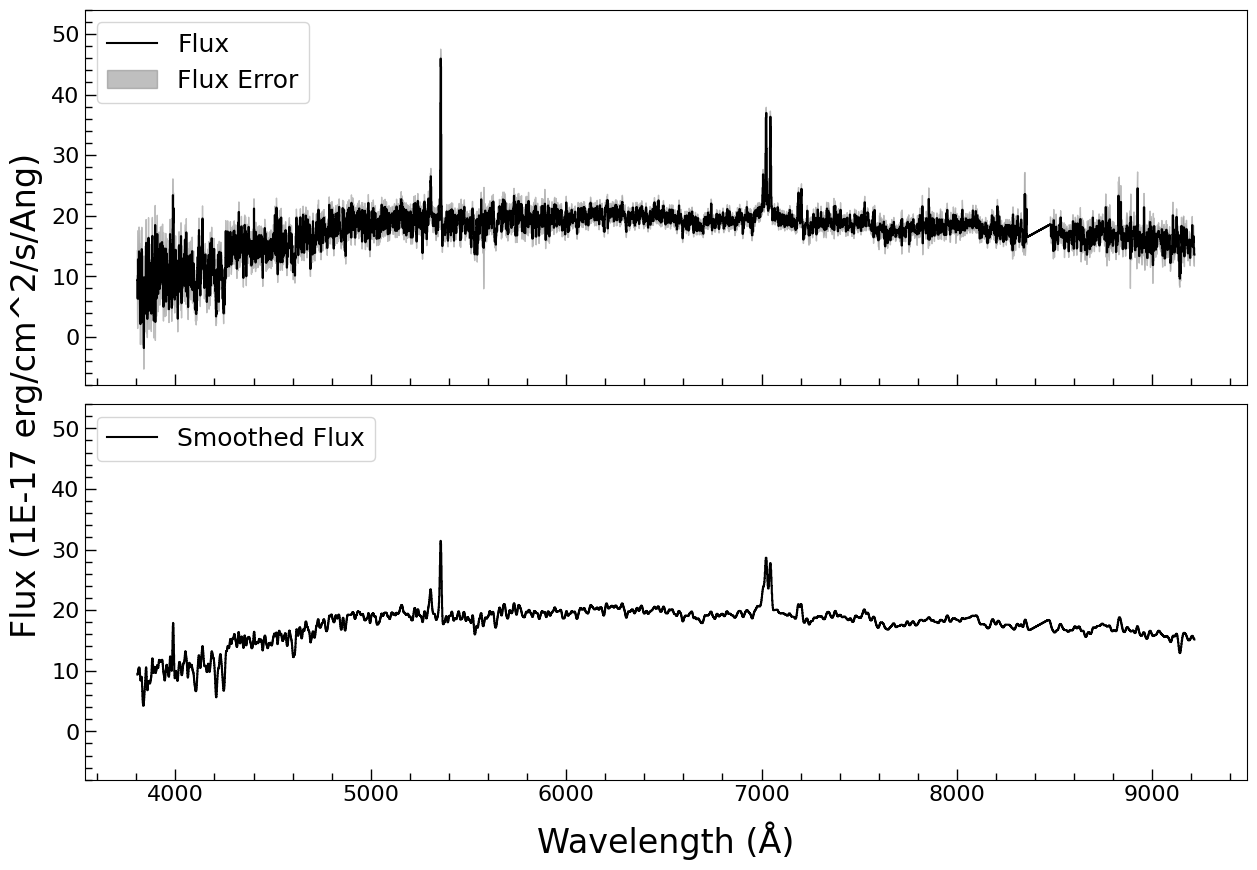

In [4]:
# %% data
# Read the data and plot

hdul = fits.open(DATA_FILE)
flux_obs = hdul[1].data['flux'].astype(float)
loglam = hdul[1].data['loglam'].astype(float)
wave_obs = 10**loglam  # Convert log wavelength to linear scale
ivar_obs = hdul[1].data['ivar'].astype(float)  # Inverse variance
with np.errstate(divide='ignore'):
    ferr_obs = np.sqrt(1/ivar_obs)  # Flux error (60 pixels have ivar = 0, i.e. no data:
                                    # an infinite error. None of them falls in a fitted window.)

units = hdul[0].header['BUNIT']
print(f"Flux units: {units}")

fig, axs = plt.subplots(2, 1, figsize=(15, 10), sharex=True, sharey=True)
fig.subplots_adjust(hspace=0.05)
axo = fig.add_subplot(111, frameon=False) # The out axis
axo.tick_params(axis='y', which='both', left=False, labelleft=False)
axo.tick_params(axis='x', which='both', bottom=False, labelbottom=False)
axo.set_xlabel(r'Wavelength (Å)', fontsize=24, labelpad=30)
axo.set_ylabel(f'Flux ({units})', fontsize=24, labelpad=30)

ax = axs[0]
ax.step(wave_obs, flux_obs, where='mid', color='k', label='Flux')
ax.fill_between(wave_obs, flux_obs - ferr_obs, flux_obs + ferr_obs, color='gray', alpha=0.5, label='Flux Error')
ax.minorticks_on()
ax.legend(loc='upper left', fontsize=18)
ax.set_ylim(-8, 54)

ax = axs[1]
flux_smooth = gaussian_filter1d(flux_obs, sigma=3)
ax.step(wave_obs, flux_smooth, where='mid', color='k', label='Smoothed Flux')
ax.legend(loc='upper left', fontsize=18)
plt.show()

### Correct the reddening and convert the wavelength to the rest frame
* The $A_V$ and the redshift are the ones the reference notebook used, from [NED](https://ned.ipac.caltech.edu/)

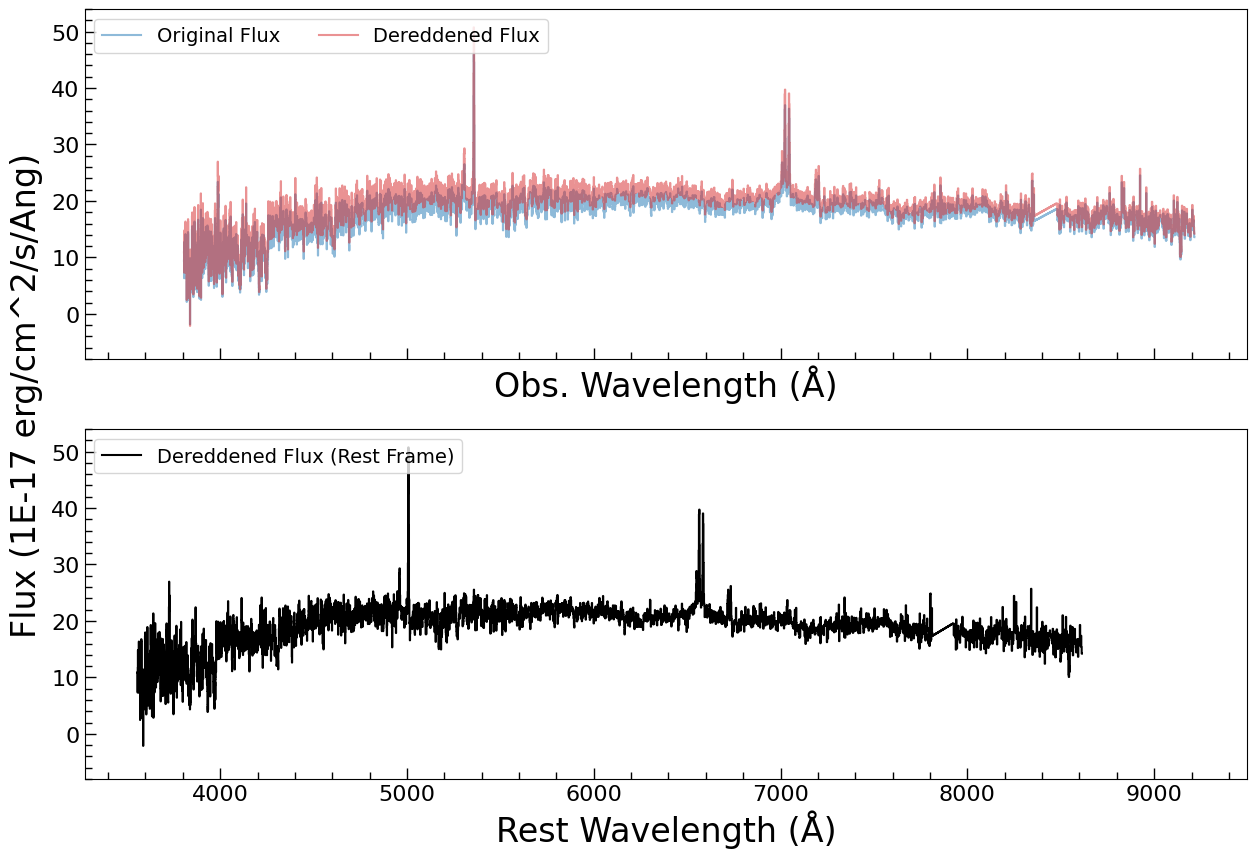

In [5]:
# %% deredden
import extinction

A_lambda = extinction.ccm89(wave_obs, A_V, r_v=3.1)
wave_rest = wave_obs / (1 + REDSHIFT)
flux_dered = flux_obs * 10**(0.4 * A_lambda)
ferr_dered = ferr_obs * 10**(0.4 * A_lambda)

fig, axs = plt.subplots(2, 1, figsize=(15, 10), sharex=True, sharey=True)
axo = fig.add_subplot(111, frameon=False) # The out axis
axo.tick_params(axis='y', which='both', left=False, labelleft=False)
axo.tick_params(axis='x', which='both', bottom=False, labelbottom=False)
axo.set_ylabel(f'Flux ({units})', fontsize=24, labelpad=30)

ax = axs[0]
ax.step(wave_obs, flux_obs, where='mid', color='C0', alpha=0.5, label='Original Flux')
ax.step(wave_obs, flux_dered, where='mid', color='C3', alpha=0.5, label='Dereddened Flux')
ax.minorticks_on()
ax.set_xlabel(r'Obs. Wavelength (Å)', fontsize=24)
ax.set_ylim(-8, 54)
ax.legend(loc='upper left', fontsize=14, ncols=3)

ax = axs[1]
ax.step(wave_rest, flux_dered, where='mid', color='k', alpha=1, label='Dereddened Flux (Rest Frame)')
ax.minorticks_on()
ax.set_xlabel(r'Rest Wavelength (Å)', fontsize=24)
ax.set_ylim(-8, 54)
ax.legend(loc='upper left', fontsize=14, ncols=3)
plt.show()

## Fit the continuum
* Measure the velocity dispersion of the host galaxy and the 5100Å monochromatic flux of the accretion disk

The components are the reference's: five stellar templates (A, F, G, K, M) that share one
velocity dispersion and one redshift offset, plus a power law for the accretion disk. Nine
free parameters in all, because the four extra stellar widths and shifts are *tied* -- a tie
removes a parameter from the prior, so the sampler never sees it.

The continuum is fitted where there is no line emission: the six windows below, with the rest
of the spectrum left out (the reference did the same with a 0/1 weight array).

`delta_z` starts at the value the SAGAN fit found ($-3.1 \times 10^{-4}$) and is bounded to
$\pm 10^{-3}$, i.e. $\pm 300$ km/s. Note that `galspec.StarSpectrum` (the astropy class)
silently drops `delta_z` passed to its constructor while the JAX class honours it, so the two
notebooks' cells are not textually identical here: `jxm.StarSpectrum` takes it directly.

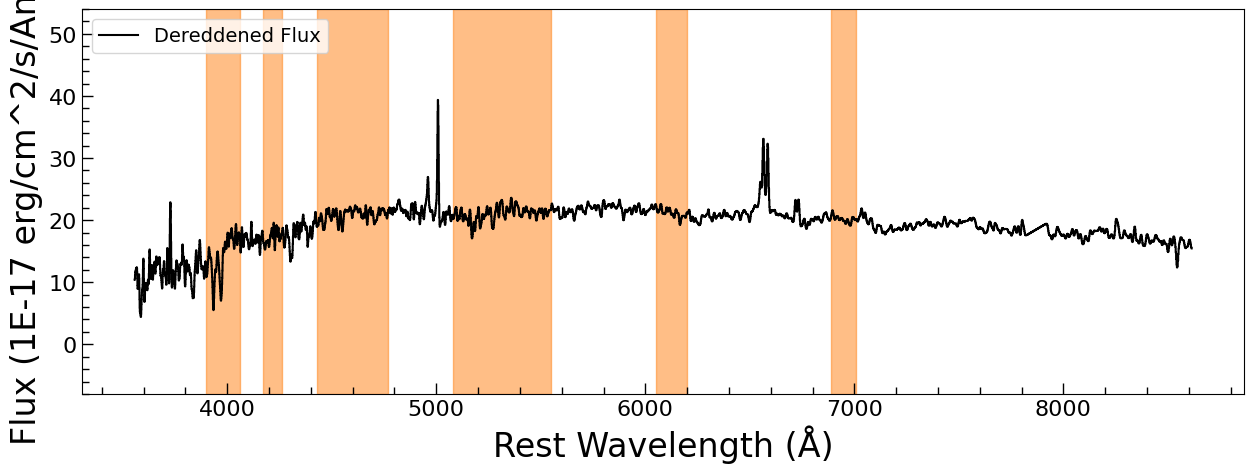

In [6]:
# %% cont_windows
# From Greene & Ho (2005, ApJ, 630, 122); The first window is to include Ca II K&H.
cont_windows = [[3900, 4060], [4170, 4260], [4430, 4770], [5080, 5550], [6050, 6200], [6890, 7010]]

fig, ax = plt.subplots(1, 1, figsize=(15, 5))
ax.step(wave_rest, gaussian_filter1d(flux_dered, 2), where='mid', color='k', label='Dereddened Flux')
for window in cont_windows:
    ax.axvspan(window[0], window[1], color='C1', alpha=0.5)
ax.set_xlabel(r'Rest Wavelength (Å)', fontsize=24)
ax.set_ylabel(f'Flux ({units})', fontsize=24)
ax.minorticks_on()
ax.set_ylim(-8, 54)
ax.legend(loc='upper left', fontsize=14)
plt.savefig(OUTPUT_DIR / 'sdss0006_continuum_fit.png', dpi=140, bbox_inches='tight')
plt.show()

In [7]:
# %% model_continuum
# ---- the stellar continuum: five templates, one width and one shift between them -----
velscale = 20                                  # km/s per template pixel
bounds = {'sigma': (velscale, 300)}            # Following Kong & Ho (2018, ApJ, 865, 116)

stars = None
for star_type, amplitude in [('A', 0.81861348), ('F', 9.00857466), ('G', 7.32022514),
                             ('K', 4.28809967), ('M', 3.73763399)]:
    star = jxm.StarSpectrum(amplitude=amplitude, sigma=79.62810518, delta_z=-0.00031473,
                            velscale=velscale, Star_type=star_type, name=f'{star_type} Star',
                            bounds=bounds)
    stars = star if stars is None else stars + star

for mn in ['A Star', 'F Star', 'G Star', 'M Star']:
    stars[mn].sigma.tied = jxm.tie_StarSpectrum_sigma('K Star')
    stars[mn].delta_z.tied = jxm.tie_StarSpectrum_deltaz('K Star')

pl = jxm.PowerLaw1D(amplitude=3.35418096, x_0=5000., alpha=-0.26414091, name='PowerLaw',
                    fixed={'x_0': True, 'alpha': False})
# The iron pseudo-continuum: this object shows no significant iron features, so it is left
# out, exactly as in the reference notebook.
model_cont = stars + pl
print(f"{len(model_cont.submodel_names)} components, "
      f"{len(model_cont.free_param_names)} free parameters: {model_cont.free_param_names}")

6 components, 9 free parameters: ('amplitude_0', 'amplitude_1', 'amplitude_2', 'amplitude_3', 'sigma_3', 'delta_z_3', 'amplitude_4', 'amplitude_5', 'alpha_5')


In [8]:
# %% priors_continuum
# ---- one prior per free parameter, scaled from the spectrum -------------------------
# A stellar amplitude and the power-law amplitude are both "a multiple of the continuum":
# any value from invisible to three times the brightest continuum pixel.
use_cont = np.zeros_like(wave_rest, dtype=bool)
for window in cont_windows:
    use_cont |= (wave_rest >= window[0]) & (wave_rest <= window[1])
weights = use_cont.astype(float)

peak_cont = float(np.max(flux_dered[use_cont]))
amp_cont = priors.LogUniform(1e-2, 3.0 * peak_cont)

for mn in ['A Star', 'F Star', 'G Star', 'K Star', 'M Star']:
    model_cont[mn].amplitude.prior = amp_cont
model_cont['PowerLaw'].amplitude.prior = amp_cont
# F_lambda ~ lambda^alpha over 3900-7000 A: every optical AGN slope in the literature is
# inside +-2, and a wider box spends its volume on slopes no AGN has -- which is what pulls
# the 5100 A level low when the slope is left free over +-5.
model_cont['PowerLaw'].alpha.prior = priors.Uniform(-2.0, 2.0)
model_cont['K Star'].sigma.prior = priors.Uniform(velscale, 300.0)
model_cont['K Star'].delta_z.prior = priors.Uniform(-0.001, 0.001)

free = set(model_cont.free_param_names)
pairs = list(zip(model_cont.param_names, model_cont.qualified_param_names))
unset = [q for flat, q in pairs if flat in free and model_cont.get_prior(q) is None]
print(f"{len(free)} free parameters; without a prior: {unset}")
assert not unset

9 free parameters; without a prior: []


In [9]:
# %% fit_continuum
started = time.perf_counter()
fit_cont = JNesty_Fit(model_cont, wave_rest[use_cont], flux_dered[use_cont],
                      ferr_dered[use_cont], nlive=nlive, bound='multi', device=DEVICE,
                      queue_size=QUEUE_SIZE)
fit_cont.fit(progress=False, dlogz=dlogz, max_iterations=MAX_ITERATIONS)
print(f"log Z = {fit_cont.log_evidence:.2f} +- {fit_cont.log_evidence_err:.2f}"
      f"   ({fit_cont.n_iterations} iterations, {(time.perf_counter() - started) / 60:.1f} min)")

# The reference prints one `m.__repr__()` per component. With a sampler the answer is a
# posterior per parameter, so the table below holds all of them: median and 16th/84th
# percentiles, which is a 68% credible interval.
lo_cont, med_cont, hi_cont = fit_cont.get_quantiles((0.16, 0.5, 0.84))
print(f"\n  {'parameter':22s} {'median':>10s} {'-':>9s} {'+':>9s}")
print("  " + "-" * 52)
for name, m, l, h in zip(fit_cont.full_param_names, med_cont, lo_cont, hi_cont):
    print(f"  {name:22s} {m:10.5g} {m - l:9.2g} {h - m:9.2g}")

model_cont.set_free_params(med_cont)          # draw the medians, not the last sample

log Z = -2047.05 +- 0.12   (78589 iterations, 3.2 min)

  parameter                  median         -         +
  ----------------------------------------------------
  A Star.amplitude          0.16686      0.11      0.25
  F Star.amplitude           9.0816      0.68      0.72
  G Star.amplitude           10.092      0.67      0.58
  K Star.amplitude           1.2311      0.53      0.68
  K Star.sigma               74.202       5.3       5.6
  K Star.delta_z         -0.00033186     2e-05     2e-05
  M Star.amplitude           3.3809      0.63      0.58
  PowerLaw.amplitude         3.5424      0.42      0.36
  PowerLaw.alpha           -0.70001      0.38      0.28


<JaxCompoundModel 6 submodels, op='+'>

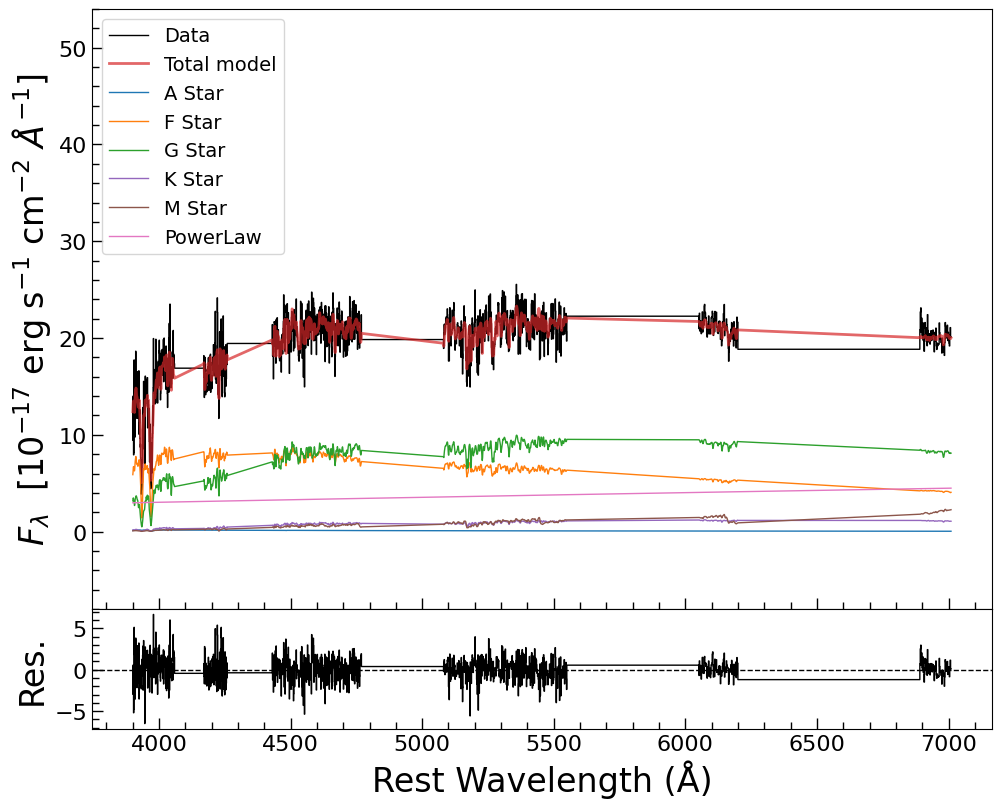

In [10]:
# %% plot_continuum
ax, axr = galspec.plot.plot_fit_jax(wave_rest[use_cont], flux_dered[use_cont], model_cont,
                                    weight=weights[use_cont], plot_weight=False,
                                    xlabel=r'Rest Wavelength (Å)', ylabel=FLUX_LABEL)
ax.set_ylim(-8, 54)
ax.legend(loc='upper left', fontsize=14)
plt.savefig(OUTPUT_DIR / 'sdss0006_continuum_fit.png', dpi=140, bbox_inches='tight')
plt.show()

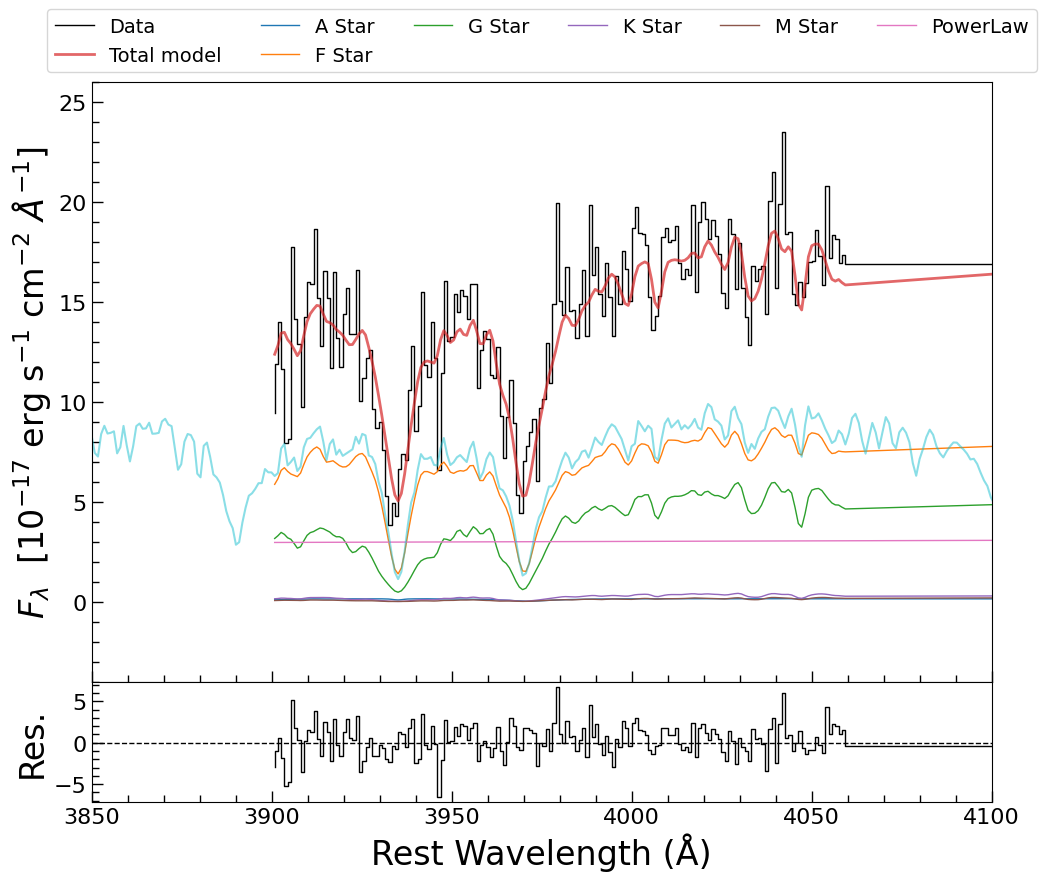

In [11]:
# %% zoom_CaII
# Zoom in the Ca II H&K region to see the absorption line width
ax, axr = galspec.plot.plot_fit_jax(wave_rest[use_cont], flux_dered[use_cont], model_cont,
                                    plot_weight=False, xlim=(3850, 4100), ylim0=(-4, 26),
                                    xlabel=r'Rest Wavelength (Å)', ylabel=FLUX_LABEL)

# the F template alone, unbroadened: what the fit's sigma does to it is the measurement
flux_F_norm = jxm.StarSpectrum(amplitude=10, sigma=0, delta_z=model_cont['F Star'].delta_z.value,
                               velscale=velscale, Star_type='F')(wave_rest)
ax.plot(wave_rest, flux_F_norm, color='C9', alpha=0.5)
ax.legend(fontsize=14, ncols=6, loc='lower center', bbox_to_anchor=(0.5, 1))
plt.show()

#### Get the emission line spectrum and the physical parameters

Subtracting the fitted continuum leaves the emission lines. Two numbers come out of this
stage: the stellar velocity dispersion $\sigma_*$ and the monochromatic luminosity
$\lambda L_\lambda(5100\,{\rm \AA})$ of the disk. Both are quoted from the posterior -- the
5100 Å level is computed *per sample*, $\mathrm{amp} \times (5100/5000)^\alpha$, because
amplitude and slope are correlated and the median of each separately is not the median of
what they describe together.

Read both with the decomposition in mind. Five templates and a power law describe one smooth
continuum, so their split is nearly free: in the run below the K-star amplitude is 1.2 where
the SAGAN fit of the same spectrum had 4.3, and the power-law slope comes out anywhere between
$-0.01$ and $-1.3$ from equally good fits. $\lambda L_\lambda(5100)$ is the robust part,
because every one of those decompositions carries the same flux at 5100 Å
($1.9$-$2.3 \times 10^{42}$ erg/s over repeated runs); $\sigma_*$ is not -- repeated runs and
two sampler configurations span 74 to 86 km/s, so its 68% interval from any one run is
narrower than the run-to-run spread, and $\pm 10$ km/s is the honest error to carry forward
to the $M_{\rm BH}-\sigma$ panel.

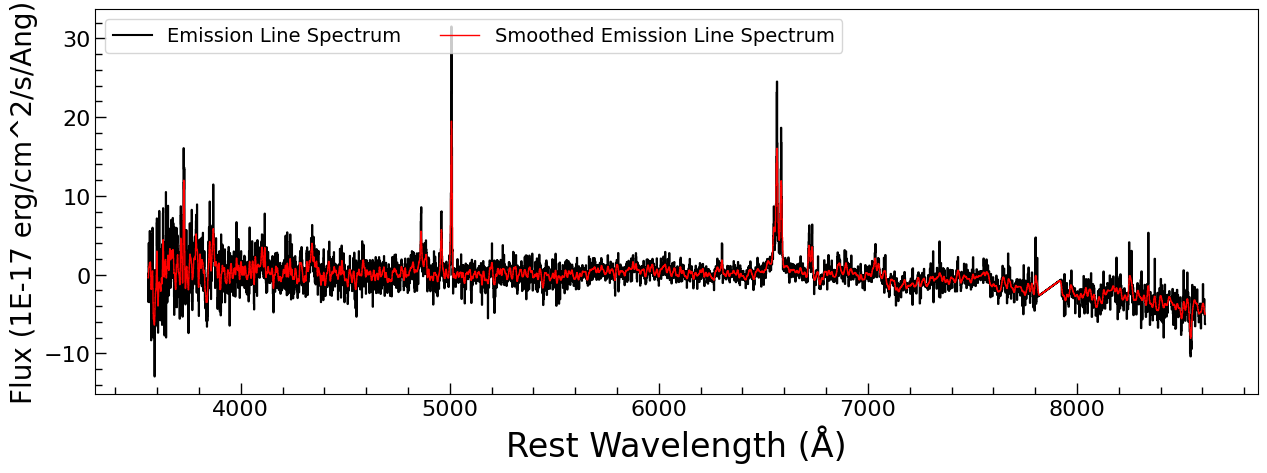


The velocity dispersion (sigma) is 74.20 (-5.27/+5.56) km/s
The 5100 Å continuum luminosity is 2.27e+42 (-2.83e+41/+2.38e+41) erg/s


In [12]:
# %% flux_lines
from astropy.cosmology import Planck18 as cosmo

flux_lines = flux_dered - model_cont(wave_rest)
fig, ax = plt.subplots(1, 1, figsize=(15, 5))
ax.step(wave_rest, flux_lines, where='mid', color='k', label='Emission Line Spectrum')
ax.step(wave_rest, gaussian_filter1d(flux_lines, 2), where='mid', lw=1, color='r', label='Smoothed Emission Line Spectrum')
ax.set_xlabel(r'Rest Wavelength (Å)', fontsize=24)
ax.set_ylabel(f'Flux ({units})', fontsize=20)
ax.minorticks_on()
ax.legend(loc='upper left', fontsize=14, ncols=2)
plt.show()

lum_dist = cosmo.luminosity_distance(REDSHIFT).to('cm').value
col_cont = {name: index for index, name in enumerate(fit_cont.param_names)}
samples_cont = np.asarray(fit_cont.samples_equal_weight, dtype=float)

# lambda L_lambda(5100): the reference's m_fit['PowerLaw'].amplitude * 5100 * 1e-17, per sample
lam_rest = 5100.0
lamFlam = (samples_cont[:, col_cont['amplitude_5']]
           * (lam_rest / 5000.0) ** samples_cont[:, col_cont['alpha_5']] * lam_rest * 1e-17)
nuLnu_samples = lamFlam * 4 * np.pi * lum_dist**2               # erg/s

sigma_star = float(np.median(samples_cont[:, col_cont['sigma_3']]))     # km/s
sigma_star_lo, sigma_star_hi = np.percentile(samples_cont[:, col_cont['sigma_3']], [16, 84])
nuLnu = float(np.median(nuLnu_samples))
nuLnu_lo, nuLnu_hi = np.percentile(nuLnu_samples, [16, 84])

print('\nThe velocity dispersion (sigma) is {:.2f} (-{:.2f}/+{:.2f}) km/s'.format(
    sigma_star, sigma_star - sigma_star_lo, sigma_star_hi - sigma_star))
print('The 5100 Å continuum luminosity is {:.2e} (-{:.2e}/+{:.2e}) erg/s'.format(
    nuLnu, nuLnu - nuLnu_lo, nuLnu_hi - nuLnu))

## Fit the emission lines
* We will measure the luminosity and line width (FWHM) of Hα, Hβ, [O III] 5007, 4959, [N II] 6583, 6548, [S II] 6716, 6731

In [13]:
# %% line_wave
# Load the wavelengths

line_wave_dict = galspec.line_wave_dict
wavec_ha = line_wave_dict['Halpha']
wavec_hb = line_wave_dict['Hbeta']
wavec_oiii_5007 = line_wave_dict['OIII_5007']
wavec_oiii_4959 = line_wave_dict['OIII_4959']
wavec_nii_6583 = line_wave_dict['NII_6583']
wavec_nii_6548 = line_wave_dict['NII_6548']
wavec_sii_6716 = line_wave_dict['SII_6716']
wavec_sii_6731 = line_wave_dict['SII_6731']

### First fit the narrow [S II] doublet as the narrow line templates

The doublet is fitted as one line with two peaks (one shared width, one shared shift) plus a
second, broader Gaussian on each peak -- a wind. The *shape* that comes out, on a velocity
grid, is the template every other narrow line will use, which is why this is measured on
[S II]: 6716 and 6731 are close enough to give two samplings of the same profile, and there is
nothing else in the window.

The continuum is fixed at zero here: `flux_lines` already has it subtracted, exactly as in the
reference notebook.

In [14]:
# %% model_sii
window = [6680, 6780]
fltr = (wave_rest > window[0]) & (wave_rest < window[1])
wave_sii = wave_rest[fltr]
flux_sii = flux_lines[fltr]
ferr_sii = ferr_dered[fltr]

cont_sii = jxm.PowerLaw1D(amplitude=0, x_0=6730., alpha=0,
                          fixed=dict(x_0=True, alpha=True, amplitude=True), name='Cont SII')
sii = jxm.Line_MultiGauss_doublet(n_components=2, amp_c0=6.12614425, amp_c1=5.85356985,
                                  dv_c=93.05894619, sigma_c=105.07513204,
                                  amp_w0=0.1, dv_w0=0, sigma_w0=200,
                                  wavec0=wavec_sii_6716, wavec1=wavec_sii_6731, name='[SII]')
model_sii = cont_sii + sii
print(f"{len(model_sii.free_param_names)} free parameters: {model_sii.free_param_names}")

7 free parameters: ('amp_c0_1', 'amp_c1_1', 'dv_c_1', 'sigma_c_1', 'amp_w0_1', 'dv_w0_1', 'sigma_w0_1')


In [15]:
# %% priors_sii
# ---- one prior per free parameter, scaled from the window ---------------------------
peak_sii = float(np.max(flux_sii))
sii.amp_c0.prior = priors.LogUniform(0.1, 3.0 * peak_sii)    # [S II] 6716
sii.amp_c1.prior = priors.LogUniform(0.1, 3.0 * peak_sii)    # [S II] 6731 (a ratio, but free:
                                                             # this is the density diagnostic)
sii.dv_c.prior = priors.Uniform(-1000.0, 1000.0)             # km/s
sii.sigma_c.prior = priors.Uniform(20.0, 300.0)              # km/s: resolved to very broad
sii.amp_w0.prior = priors.Uniform(1e-3, 1.0)                 # the wing, as a ratio to the core
sii.dv_w0.prior = priors.Uniform(-1000.0, 1000.0)
sii.sigma_w0.prior = priors.Uniform(20.0, 300.0)

free = set(model_sii.free_param_names)
pairs = list(zip(model_sii.param_names, model_sii.qualified_param_names))
unset = [q for flat, q in pairs if flat in free and model_sii.get_prior(q) is None]
print(f"{len(free)} free parameters; without a prior: {unset}")
assert not unset

7 free parameters; without a prior: []


log Z = -94.58 +- 0.08   (41276 iterations, 0.5 min)

  parameter                  median         -         +
  ----------------------------------------------------
  [SII].amp_c0               5.2691       1.4      0.91
  [SII].amp_c1               5.2016       1.3      0.89
  [SII].dv_c                 95.613        15        17
  [SII].sigma_c              101.96        15        12
  [SII].amp_w0              0.18895      0.16      0.59
  [SII].dv_w0                -62.06   5.9e+02   1.7e+02
  [SII].sigma_w0             105.64        63        50


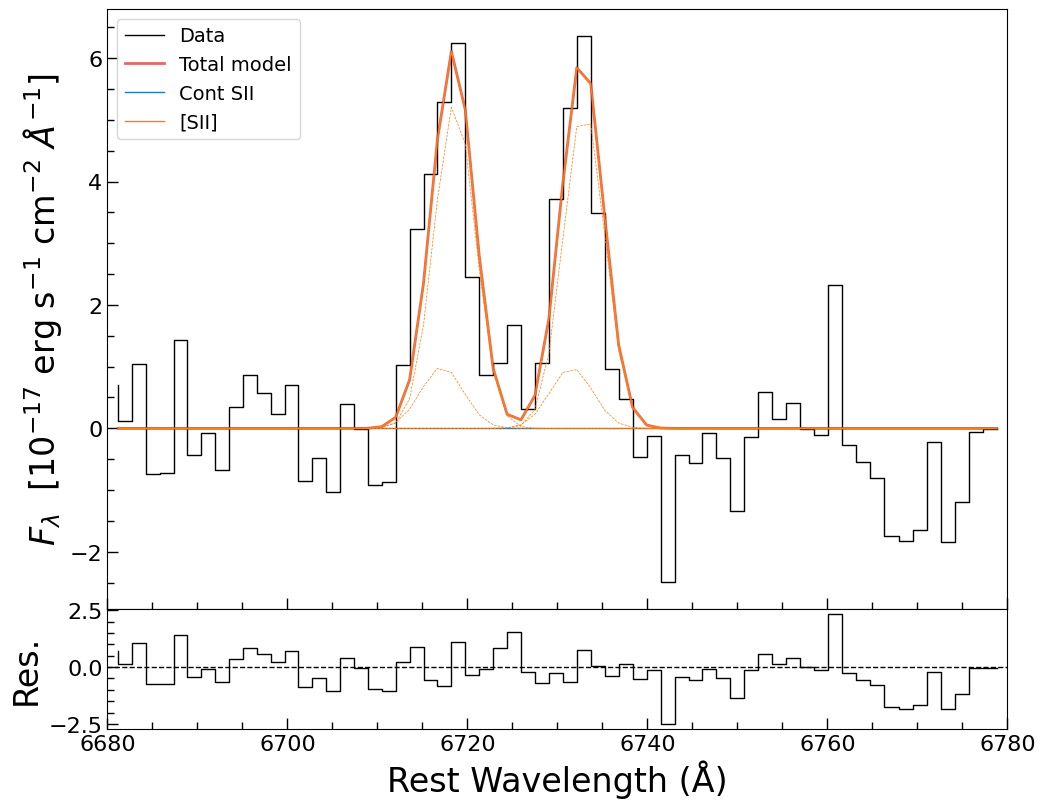

In [16]:
# %% fit_sii
started = time.perf_counter()
fit_sii = JNesty_Fit(model_sii, wave_sii, flux_sii, ferr_sii, nlive=nlive, bound='multi',
                     device=DEVICE, queue_size=QUEUE_SIZE)
fit_sii.fit(progress=False, dlogz=dlogz, max_iterations=MAX_ITERATIONS)
print(f"log Z = {fit_sii.log_evidence:.2f} +- {fit_sii.log_evidence_err:.2f}"
      f"   ({fit_sii.n_iterations} iterations, {(time.perf_counter() - started) / 60:.1f} min)")

lo_sii, med_sii, hi_sii = fit_sii.get_quantiles((0.16, 0.5, 0.84))
print(f"\n  {'parameter':22s} {'median':>10s} {'-':>9s} {'+':>9s}")
print("  " + "-" * 52)
for name, m, l, h in zip(fit_sii.full_param_names, med_sii, lo_sii, hi_sii):
    print(f"  {name:22s} {m:10.5g} {m - l:9.2g} {h - m:9.2g}")

model_sii.set_free_params(med_sii)

ax, axr = galspec.plot.plot_fit_jax(wave_sii, flux_sii, model_sii, xlim=window,
                                    xlabel=r'Rest Wavelength (Å)', ylabel=FLUX_LABEL)
ax.legend(fontsize=14, ncols=1, loc='upper left')   # the peaks are on the right
plt.savefig(OUTPUT_DIR / 'sdss0006_sii_fit.png', dpi=140, bbox_inches='tight')
plt.show()

template: 1200 velocity bins, peak 1.000, FWHM 240 km/s
  wrote /home/shangguan/Softwares/my_modules/GalSpec/example/output/sdss0006_sii_template.txt


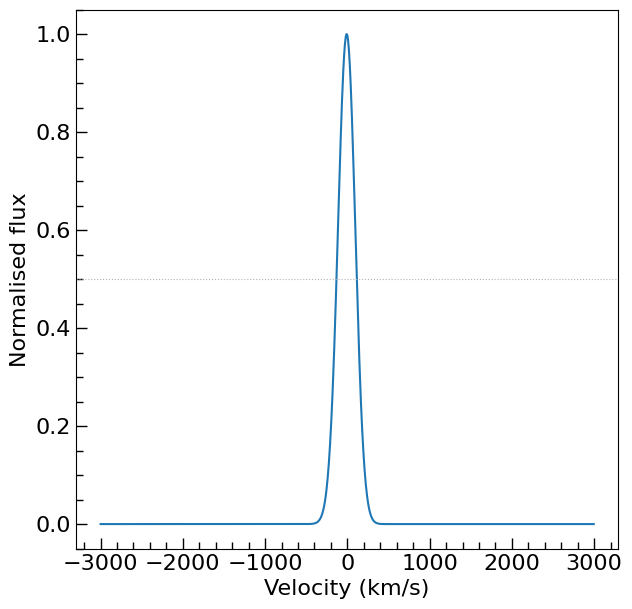

In [17]:
# %% template
# Generate the narrow line template: the fitted doublet's *single-line* profile in velocity
# space, unit peak.  gen_template reads the current parameters, and the medians are on the
# model since the fit cell above, so this is the measured profile -- not a Gaussian.
ls_km = galspec.constants.ls_km

velc_temp = np.arange(-3e3, 3e3, 5)
flux_temp = np.asarray(model_sii['[SII]'].gen_template(velc_temp))
temp_data = np.array([velc_temp, flux_temp]).T
np.savetxt(OUTPUT_DIR / 'sdss0006_sii_template.txt', temp_data, fmt='%5e')

half = np.where(flux_temp >= 0.5)[0]
print(f"template: {flux_temp.size} velocity bins, peak {flux_temp.max():.3f}, "
      f"FWHM {velc_temp[half[-1]] - velc_temp[half[0]]:.0f} km/s")
print(f"  wrote {OUTPUT_DIR / 'sdss0006_sii_template.txt'}")

fig, ax = plt.subplots(figsize=(7, 7))
ax.plot(velc_temp, flux_temp)
ax.axhline(0.5, color='0.7', lw=0.8, ls=':')
ax.set_xlabel('Velocity (km/s)', fontsize=16)
ax.set_ylabel('Normalised flux', fontsize=16)
ax.minorticks_on()
plt.savefig(OUTPUT_DIR / 'sdss0006_sii_template_profile.png', dpi=140, bbox_inches='tight')
plt.show()

### Fit the Hα complex

Five lines on three components: broad Hα (a Gaussian, since the broad-line region does not
share the narrow kinematics), and the narrow lines -- Hα on its own, plus [N II] 6548+6583
and [S II] 6716+6731 as two `Line_template_doublet`s -- every one of them the template
measured above and shifted by *one* velocity, because the NLR moves as one body.

The doublets are doublets *in the model*: `amp_c1` is tied to `amp_c0/2.96` for [N II], which
is atomic physics, and left free for [S II], where that ratio is the density diagnostic. Eight
free parameters for five lines, where ten Gaussians would have needed thirty; `single()` then
picks out 6583 and each [S II] line when their fluxes are measured below.

In [18]:
# %% model_ha
window = [6400, 6900]
fltr = (wave_rest > window[0]) & (wave_rest < window[1])
wave_ha = wave_rest[fltr]
flux_ha = flux_lines[fltr]
ferr_ha = ferr_dered[fltr]

bha = jxm.Line_MultiGauss(n_components=1, amp_c=4.03952323, dv_c=150.30995833,
                          sigma_c=1102.23008001, wavec=wavec_ha, name='bHalpha')
nha = jxm.Line_template(template_velc=velc_temp, template_flux=flux_temp,
                        amplitude=16.99272669, dv=86.18868006, wavec=wavec_ha, name='nHalpha')
# The two narrow doublets: one template doublet each, so the shared shift is structural and
# the pair cannot drift apart.  line.single(wave, comp) then gives one line of it.
nii = jxm.Line_template_doublet(template_velc=velc_temp, template_flux=flux_temp,
                                amp_c0=16.55604126, amp_c1=16.55604126 / 2.96, dv_c=0,
                                wavec0=wavec_nii_6583, wavec1=wavec_nii_6548, name='NII')
sii = jxm.Line_template_doublet(template_velc=velc_temp, template_flux=flux_temp,
                                amp_c0=5.23636479, amp_c1=5.65680966, dv_c=0,
                                wavec0=wavec_sii_6716, wavec1=wavec_sii_6731, name='SII')

model_ha = bha + nha + nii + sii

# Tie the parameters: one velocity for every narrow line, and the [N II] doublet ratio
for ln in ['NII', 'SII']:
    model_ha[ln].dv_c.tied = jxm.tie.tie_template_dv('nHalpha')

model_ha['NII'].amp_c1.tied = jxm.tie.tie_MultiGauss_doublet_ratio('NII', ratio=2.96)
# ([S II] 6716/6731 is a density diagnostic, not an atomic ratio: it stays free)

print(f"{len(model_ha.free_param_names)} free parameters: {model_ha.free_param_names}")

8 free parameters: ('amp_c_0', 'dv_c_0', 'sigma_c_0', 'amplitude_1', 'dv_1', 'amp_c0_2', 'amp_c0_3', 'amp_c1_3')


In [19]:
# %% priors_ha
# ---- one prior per free parameter, scaled from the window ---------------------------
peak_ha = float(np.max(flux_ha))
bha.amp_c.prior = priors.LogUniform(0.1, 3.0 * peak_ha)
bha.dv_c.prior = priors.Uniform(-1000.0, 1000.0)        # km/s
bha.sigma_c.prior = priors.Uniform(300.0, 6000.0)       # km/s: broader than any narrow line
nha.amplitude.prior = priors.LogUniform(0.1, 3.0 * peak_ha)
nha.dv.prior = priors.Uniform(-500.0, 500.0)            # the systemic velocity, all narrow lines
nii.amp_c0.prior = priors.LogUniform(0.1, 3.0 * peak_ha)
sii.amp_c0.prior = priors.LogUniform(0.1, 3.0 * peak_ha)
sii.amp_c1.prior = priors.LogUniform(0.1, 3.0 * peak_ha)    # the ratio is measured, not fixed
# (the parameters that are tied in the cell above take no prior: their value never comes
# from the prior, and galspec raises if one is set)

free = set(model_ha.free_param_names)
pairs = list(zip(model_ha.param_names, model_ha.qualified_param_names))
unset = [q for flat, q in pairs if flat in free and model_ha.get_prior(q) is None]
print(f"{len(free)} free parameters; without a prior: {unset}")
assert not unset

8 free parameters; without a prior: []


log Z = -454.60 +- 0.11   (67551 iterations, 0.9 min)

  parameter                  median         -         +
  ----------------------------------------------------
  bHalpha.amp_c              3.3818      0.27      0.29
  bHalpha.dv_c               96.659        78        76
  bHalpha.sigma_c            1247.9   1.1e+02   1.2e+02
  nHalpha.amplitude          21.146      0.73      0.73
  nHalpha.dv                 94.851       2.8       2.8
  NII.amp_c0                 15.526      0.62      0.63
  SII.amp_c0                 6.0437      0.53      0.54
  SII.amp_c1                 5.8324      0.53      0.54


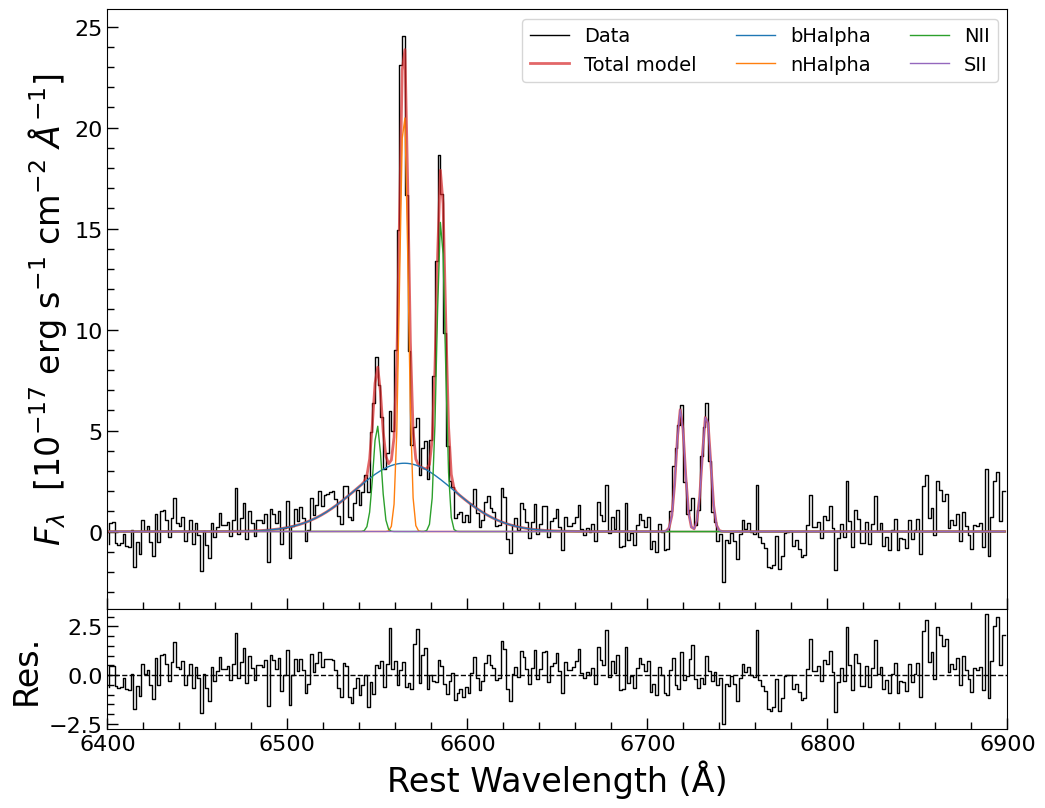

In [20]:
# %% fit_ha
started = time.perf_counter()
fit_ha = JNesty_Fit(model_ha, wave_ha, flux_ha, ferr_ha, nlive=nlive, bound='multi',
                    device=DEVICE, queue_size=QUEUE_SIZE)
fit_ha.fit(progress=False, dlogz=dlogz, max_iterations=MAX_ITERATIONS)
print(f"log Z = {fit_ha.log_evidence:.2f} +- {fit_ha.log_evidence_err:.2f}"
      f"   ({fit_ha.n_iterations} iterations, {(time.perf_counter() - started) / 60:.1f} min)")

lo_ha, med_ha, hi_ha = fit_ha.get_quantiles((0.16, 0.5, 0.84))
print(f"\n  {'parameter':22s} {'median':>10s} {'-':>9s} {'+':>9s}")
print("  " + "-" * 52)
for name, m, l, h in zip(fit_ha.full_param_names, med_ha, lo_ha, hi_ha):
    print(f"  {name:22s} {m:10.5g} {m - l:9.2g} {h - m:9.2g}")

model_ha.set_free_params(med_ha)

ax, axr = galspec.plot.plot_fit_jax(wave_ha, flux_ha, model_ha, xlim=window,
                                    xlabel=r'Rest Wavelength (Å)', ylabel=FLUX_LABEL)
ax.legend(fontsize=14, ncols=3, loc='upper right')
plt.savefig(OUTPUT_DIR / 'sdss0006_halpha_fit.png', dpi=140, bbox_inches='tight')
plt.show()

### Add the Hβ complex

Hβ, the [O III] doublet and the broad [O III] wing join the model, and the whole thing is
fitted again over both windows at once -- the Hα complex comes along as it is, so the narrow
lines keep one velocity across the two windows. [O III] arrives as one more
`Line_template_doublet`, with its 4959 amplitude tied to 5007/2.98; Hβ shares broad Hα's shift
(`dv_c` tied) but not its width, which is a measurement.

One prior is tighter than it looks: the wing's amplitude is bounded to half the peak of the
window. The wing and the template sit at the same wavelength, so a wing free to grow to the
line's strength makes the two labels interchangeable -- the sampler then sometimes answers
with a 30× stronger "wing" and a starved narrow line, which puts the [O III] flux measured
below two orders of magnitude too low. Half the peak still leaves room for a broad base a
third of the line's height, and it removes that mode.

**One tie fixed.** The reference tied the wing's `dv_c` to `amp_c0 / 2.98` -- `tie_MultiGauss_doublet_ratio`
returns an amplitude ratio, so that cell drove the wing's velocity shift to
$0.21$ km/s instead of tying anything physical (its printed `dv_c=0.213` is exactly
`amp_c0/2.98`). Here the wing is built with `wavec0 = 5007` and its 4959 amplitude tied to
$1/2.98$ of it, which is what the ratio was for, and its shift is tied to the narrow lines'
systemic velocity like every other narrow line.

In [21]:
# %% model_hb
window_list = [[4700, 5100], [6400, 6900]]
fltr = np.zeros_like(wave_rest, dtype=bool)
for window in window_list:
    fltr |= (wave_rest > window[0]) & (wave_rest < window[1])
wave_hb = wave_rest[fltr]
flux_hb = flux_lines[fltr]
ferr_hb = ferr_dered[fltr]

bhb = jxm.Line_MultiGauss(n_components=1, amp_c=3.29861897, dv_c=98.83475277,
                          sigma_c=1272.70115266, wavec=wavec_hb, name='bHbeta')
nhb = jxm.Line_template(template_velc=velc_temp, template_flux=flux_temp,
                        amplitude=16.99272669, dv=86.18868006, wavec=wavec_hb, name='nHbeta')
# the [O III] doublet, one template doublet with the atomic ratio imposed below
oiii = jxm.Line_template_doublet(template_velc=velc_temp, template_flux=flux_temp,
                                 amp_c0=16.55604126, amp_c1=16.55604126 / 2.98, dv_c=0,
                                 wavec0=wavec_oiii_5007, wavec1=wavec_oiii_4959, name='OIII')
# the broad [O III] wing: a Gaussian at each peak of the doublet
no3_w = jxm.Line_MultiGauss_doublet(n_components=1, amp_c0=3.0, amp_c1=3.0/2.98, dv_c=0,
                                    sigma_c=300, wavec0=wavec_oiii_5007,
                                    wavec1=wavec_oiii_4959, name='OIII_w')

model_hb = bhb + nhb + oiii + no3_w + model_ha     # the fitted H-alpha complex comes along

# Tie the parameters
model_hb['nHbeta'].dv.tied = jxm.tie.tie_template_dv('nHalpha')
model_hb['OIII'].dv_c.tied = jxm.tie.tie_template_dv('nHalpha')
model_hb['OIII'].amp_c1.tied = jxm.tie.tie_MultiGauss_doublet_ratio('OIII', ratio=2.98)
model_hb['OIII_w'].amp_c1.tied = jxm.tie.tie_MultiGauss_doublet_ratio('OIII_w', ratio=2.98)
model_hb['OIII_w'].dv_c.tied = jxm.tie.tie_template_dv('nHalpha')
model_hb['bHbeta'].dv_c.tied = jxm.tie.tie_MultiGauss_dv_c('bHalpha')

print(f"{len(model_hb.free_param_names)} free parameters: {model_hb.free_param_names}")

14 free parameters: ('amp_c_0', 'sigma_c_0', 'amplitude_1', 'amp_c0_2', 'amp_c0_3', 'sigma_c_3', 'amp_c_4', 'dv_c_4', 'sigma_c_4', 'amplitude_5', 'dv_5', 'amp_c0_6', 'amp_c0_7', 'amp_c1_7')


In [22]:
# %% priors_hb
# ---- one prior per free parameter, scaled from the two windows ----------------------
peak_hb = float(np.max(flux_hb))
bhb.amp_c.prior = priors.LogUniform(0.1, 3.0 * peak_hb)
bhb.sigma_c.prior = priors.Uniform(300.0, 6000.0)       # km/s
nhb.amplitude.prior = priors.LogUniform(0.1, 3.0 * peak_hb)
oiii.amp_c0.prior = priors.LogUniform(0.1, 3.0 * peak_hb)
# The wing stops at half the peak (see the note above this cell): it sits at the same
# wavelength as the template, so a wing free to reach the line's strength can absorb the line.
no3_w.amp_c0.prior = priors.LogUniform(0.1, 0.5 * peak_hb)   # a broad base, not the line
no3_w.sigma_c.prior = priors.Uniform(30.0, 2000.0)      # km/s: a wing, not a line core
# (the parameters that are tied in the cell above take no prior: their value never comes
# from the prior, and galspec raises if one is set)

free = set(model_hb.free_param_names)
pairs = list(zip(model_hb.param_names, model_hb.qualified_param_names))
unset = [q for flat, q in pairs if flat in free and model_hb.get_prior(q) is None]
print(f"{len(free)} free parameters; without a prior: {unset}")
assert not unset

14 free parameters; without a prior: []


log Z = -1070.14 +- 0.14   (96265 iterations, 1.5 min)



  parameter                  median         -         +
  ----------------------------------------------------
  bHbeta.amp_c               1.4843      0.27      0.28
  bHbeta.sigma_c             1457.8   2.5e+02     3e+02
  nHbeta.amplitude           6.6369      0.86      0.86
  OIII.amp_c0                30.838       1.2         1
  OIII_w.amp_c0             0.37986      0.22      0.66
  OIII_w.sigma_c              508.4   2.5e+02   6.1e+02
  bHalpha.amp_c              3.3773      0.28      0.28
  bHalpha.dv_c               104.95        74        73
  bHalpha.sigma_c            1251.2   1.1e+02   1.2e+02
  nHalpha.amplitude           21.11      0.71      0.71
  nHalpha.dv                 90.502       2.4       2.4
  NII.amp_c0                 15.494      0.59      0.63
  SII.amp_c0                 5.9714      0.55      0.54
  SII.amp_c1                 5.8079      0.53      0.52


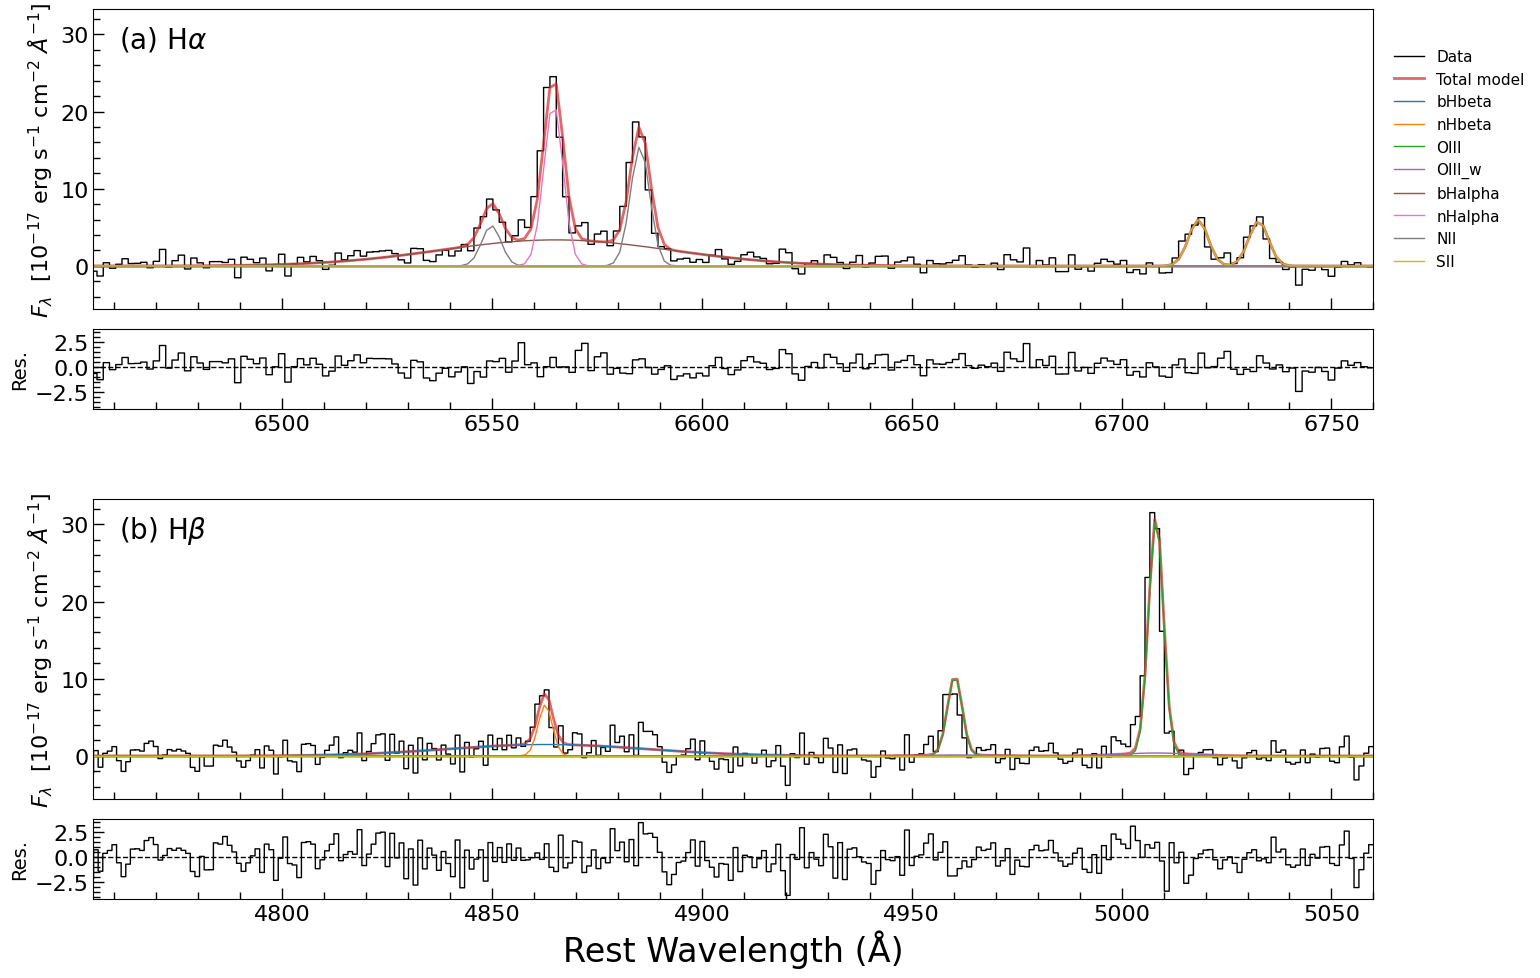

In [23]:
# %% fit_hb
started = time.perf_counter()
fit_hb = JNesty_Fit(model_hb, wave_hb, flux_hb, ferr_hb, nlive=nlive, bound='multi',
                    device=DEVICE, queue_size=QUEUE_SIZE)
fit_hb.fit(progress=False, dlogz=dlogz, max_iterations=MAX_ITERATIONS)
print(f"log Z = {fit_hb.log_evidence:.2f} +- {fit_hb.log_evidence_err:.2f}"
      f"   ({fit_hb.n_iterations} iterations, {(time.perf_counter() - started) / 60:.1f} min)")

lo_hb, med_hb, hi_hb = fit_hb.get_quantiles((0.16, 0.5, 0.84))
print(f"\n  {'parameter':22s} {'median':>10s} {'-':>9s} {'+':>9s}")
print("  " + "-" * 52)
for name, m, l, h in zip(fit_hb.full_param_names, med_hb, lo_hb, hi_hb):
    print(f"  {name:22s} {m:10.5g} {m - l:9.2g} {h - m:9.2g}")

model_hb.set_free_params(med_hb)

fig = plt.figure(figsize=(16, 10))
ax00 = fig.add_axes([0.08, 0.66, 0.80, 0.30])
ax01 = fig.add_axes([0.08, 0.56, 0.80, 0.08])
ax10 = fig.add_axes([0.08, 0.17, 0.80, 0.30])
ax11 = fig.add_axes([0.08, 0.07, 0.80, 0.08])

ax, axr = galspec.plot.plot_fit_jax(wave_hb, flux_hb, model_hb, ax=ax00, axr=ax01,
                                    xlim=[6455, 6760], xlabel='', ylabel='')
ax.set_ylabel(FLUX_LABEL, fontsize=16)
ax.legend(loc='center left', bbox_to_anchor=(1.005, 0.5), fontsize=11, ncols=1, frameon=False)
ax01.set_ylabel('Res.', fontsize=14)
ax00.text(0.02, 0.95, r'(a) H$\alpha$', transform=ax00.transAxes, fontsize=20, va='top', ha='left')

ax, axr = galspec.plot.plot_fit_jax(wave_hb, flux_hb, model_hb, ax=ax10, axr=ax11,
                                    xlim=[4755, 5060], xlabel=r'Rest Wavelength (Å)',
                                    ylabel=FLUX_LABEL)
ax.set_ylabel(FLUX_LABEL, fontsize=16)
ax.legend_.remove()                      # the same components as panel (a)
ax11.set_ylabel('Res.', fontsize=14)
ax10.text(0.02, 0.95, r'(b) H$\beta$', transform=ax10.transAxes, fontsize=20, va='top', ha='left')
fig.savefig(OUTPUT_DIR / 'sdss0006_hbeta_halpha_fit.png', dpi=140, bbox_inches='tight')
plt.show()

### Calculate the physical parameters

A flux is a combination of parameters, so it is computed for every posterior sample rather
than from the medians -- that is how the error bar inherits the correlations in the fit. The
two functions below are the reference's, with the parameter vector as the argument: setting
`model_hb.set_free_params(theta)` puts one sample on the model (ties included), and the
submodel is then evaluated on its own.

The observed wavelengths `wave_obs` are used for the integral, as in the reference: a velocity
width is frame-independent once the model is written in the rest frame, so integrating over
either grid gives the same flux.

Two of the components are doublets, and a flux is per *line*: [N II] 6583 alone enters the BPT
diagram, and the [S II] ratio needs 6716 and 6731 separately. `Line_template_doublet.single(
wave, comp)` returns one line of a doublet at the model's current values, so both functions
take a `comp`: `None` for a component that is a single line, `0`/`1` for one line of a
doublet. Integrating a doublet whole would put 6548 into the [N II] flux.

In [24]:
# %% physical_parameters
def integrate_line_flux(model, line_name, wave_obs, theta, scale=1e-17, comp=None):
    """
    Integrate the line flux from the fitted model.

    Parameters:
    model : JaxModel
        The fitted model containing the emission line.
    line_name : str
        The name of the emission line to integrate.
    wave_obs : array-like
        Very important! We should use the observed wavelength array.
    theta : array-like
        One posterior sample: the free parameters of the model.
    scale : float, optional
        The scale factor to convert the flux units, default is 1e-17 erg/s/cm^2/Å.
    comp : int, optional
        For a doublet, which line to take: 0 for the line at ``wavec0``, 1 for the
        one at ``wavec1``.  ``None`` (the default) integrates everything under
        ``line_name``, which for a doublet is both peaks.

    Returns:
    line_flux : float
        The integrated line flux in erg/s/cm^2.
    """
    model.set_free_params(theta)                     # ties are resolved here
    line = model[line_name]
    flux = line(wave_obs) if comp is None else line.single(wave_obs, comp)
    return np.trapezoid(np.asarray(flux) * scale, wave_obs)


def cal_fwhm(model, line_name, theta, vlim=10000, comp=None):
    """
    Calculate the FWHM of the emission line from the fitted model.
    This function allows for complex line profiles.

    Parameters:
    model : JaxModel
        The fitted model containing the emission line.
    line_name : str
        The name of the emission line to calculate FWHM.
    theta : array-like
        One posterior sample: the free parameters of the model.
    comp : int, optional
        For a doublet, which line to measure.  ``None`` measures the first line of
        a doublet (the width of both peaks together is not a line width).

    Returns:
    fwhm : float
        The FWHM of the emission line in km/s.
    """
    model.set_free_params(theta)
    line = model[line_name]
    if comp is None and 'wavec' not in line.param_names:
        comp = 0                                     # a doublet: measure it line by line
    centre = float(line.wavec.value) if comp is None else \
        float(line.wavec0.value if comp == 0 else line.wavec1.value)
    velc = np.linspace(-vlim, vlim, 10000)
    wave = (1 + velc / ls_km) * centre
    flux = np.asarray(line(wave) if comp is None else line.single(wave, comp))
    half_max = np.max(flux) / 2
    indices = np.where(flux >= half_max)[0]
    return velc[indices[-1]] - velc[indices[0]]


samples_hb = np.asarray(fit_hb.samples_equal_weight, dtype=float)

# A flux and a width are evaluations of the model, and the posterior has one entry per dead
# point -- tens of thousands of them.  Two thousand draws resolve a 16th/84th percentile to
# well under a percent and take seconds instead of minutes, so the tail is thinned here.
# (The percentile error of a 2000-draw quantile is sqrt(p(1-p)/n) ~ 0.9%.)
step = max(1, samples_hb.shape[0] // 2000)
samples_hb = samples_hb[::step]

# Each quantity names the model component it comes from, and for a doublet which line of it:
# a BPT diagram wants [N II] 6583, not 6583+6548, and both [S II] lines for the ratio.
LINE_SPECS = [('bHbeta', 'bHbeta', None),
              ('bHalpha', 'bHalpha', None),
              ('nHbeta', 'nHbeta', None),
              ('nHalpha', 'nHalpha', None),
              ('OIII_5007', 'OIII', 0),
              ('NII_6583', 'NII', 0),
              ('SII_6716', 'SII', 0),
              ('SII_6731', 'SII', 1)]
print(f"fluxes and widths from {samples_hb.shape[0]} of the posterior samples")

# the posterior (the reference reads these off one best-fit model)
line_flux = {key: np.array([integrate_line_flux(model_hb, name, wave_obs, theta, comp=comp)
                            for theta in samples_hb])
             for key, name, comp in LINE_SPECS}
line_flux['SII'] = line_flux['SII_6716'] + line_flux['SII_6731']
fwhm_ha = np.array([cal_fwhm(model_hb, 'bHalpha', theta) for theta in samples_hb])
fwhm_hb = np.array([cal_fwhm(model_hb, 'bHbeta', theta) for theta in samples_hb])
fwhm_narrow = np.array([cal_fwhm(model_hb, 'OIII', theta, comp=0) for theta in samples_hb])

# The broad and the narrow Balmer lines are kept apart: the black-hole mass wants the broad
# width, the BPT diagram wants narrow-line ratios, and a Balmer decrement means one or the
# other -- never their sum.
flux_bhb = line_flux['bHbeta']
flux_bha = line_flux['bHalpha']
flux_nhb = line_flux['nHbeta']
flux_nha = line_flux['nHalpha']
flux_o3 = line_flux['OIII_5007']
flux_n2 = line_flux['NII_6583']
flux_s2 = line_flux['SII']

# Calculate the BH mass.  nuLnu comes from the continuum stage and fwhm_hb from this one; the
# two posteriors are independent fits, so the pairs below are drawn at random and the quoted
# error carries both stages -- it does not carry any correlation between them, which a staged
# fit cannot see.
rng = np.random.default_rng(0)
logMbh = np.log10((fwhm_hb / 1000)**2 * (nuLnu_samples[rng.integers(0, nuLnu_samples.size, fwhm_hb.size)] / 1e44)**0.533) + 6.91  # Equation (2) of Liu et al. (2019, ApJS, 243, 21)


def line_summary(values):
    lo, med, hi = np.percentile(values, [16, 50, 84])
    return f"{med:12.4g}  -{med - lo:.3g}/+{hi - med:.3g}"


print(f"  {'quantity':22s} {'value':>12s}  68% interval   (flux: erg/s/cm2, width: km/s)")
print("  " + "-" * 80)
for name, values in [('F(H-beta) broad', flux_bhb),
                     ('F(H-alpha) broad', flux_bha),
                     ('F(H-beta) narrow', flux_nhb),
                     ('F(H-alpha) narrow', flux_nha),
                     ('F([O III] 5007)', flux_o3),
                     ('F([N II] 6583)', flux_n2),
                     ('F([S II] 6716+6731)', flux_s2),
                     ('FWHM(H-alpha) broad', fwhm_ha),
                     ('FWHM(H-beta) broad', fwhm_hb),
                     ('log M_BH [M_sun]', logMbh)]:
    print(f"  {name:22s} {line_summary(values)}")
print(f"  {'FWHM([O III]) [km/s]':22s} {np.median(fwhm_narrow):12.0f}"
      "  (the template's shape: no width is fitted)")

fluxes and widths from 2006 of the posterior samples


  quantity                      value  68% interval   (flux: erg/s/cm2, width: km/s)
  --------------------------------------------------------------------------------
  F(H-beta) broad           8.772e-16  -1.48e-16/+1.54e-16
  F(H-alpha) broad          2.315e-15  -1.28e-16/+1.39e-16
  F(H-beta) narrow          2.821e-16  -3.76e-17/+3.58e-17
  F(H-alpha) narrow         1.215e-15  -4.11e-17/+4.19e-17
  F([O III] 5007)           1.354e-15  -5.52e-17/+4.6e-17
  F([N II] 6583)            8.951e-16  -3.46e-17/+3.6e-17
  F([S II] 6716+6731)       6.951e-16  -4.71e-17/+4.53e-17
  FWHM(H-alpha) broad            2946  -254/+300
  FWHM(H-beta) broad             3430  -624/+716
  log M_BH [M_sun]              7.101  -0.173/+0.166
  FWHM([O III]) [km/s]            244  (the template's shape: no width is fitted)


## Analyze the physical properties of this target

### The BPT diagram
* Read this [Annual Review for Astronomy and Astrophysics paper](https://scixplorer.org/abs/2019ARA&A..57..511K/abstract) to learn more

Two ratios of forbidden-to-recombination lines, both measured off the model: [N II] 6583 over
Hα, and [O III] 5007 over Hβ. The forbidden lines come from the narrow-line region only, so the
Balmer denominator is the *narrow* component too. That is not a detail of bookkeeping: the
broad lines are gas at a different radius, and putting them in the denominator dilutes both
ratios until a Seyfert 1 lands in the star-forming corner -- which is exactly what happens with
the reference notebook's choice of denominator. With the narrow flux the object sits well
above the Kewley line, as a 2 800 km/s broad Hα and [O III]/Hβ ~ 5 should.

The Liu et al. (2019) AGN sample is the background the reference notebook plots; it lives in
`develop/temp/` in this checkout. The star is this object, at the medians of the flux ratios,
with the 16th/84th percentile of each ratio as its error bar.

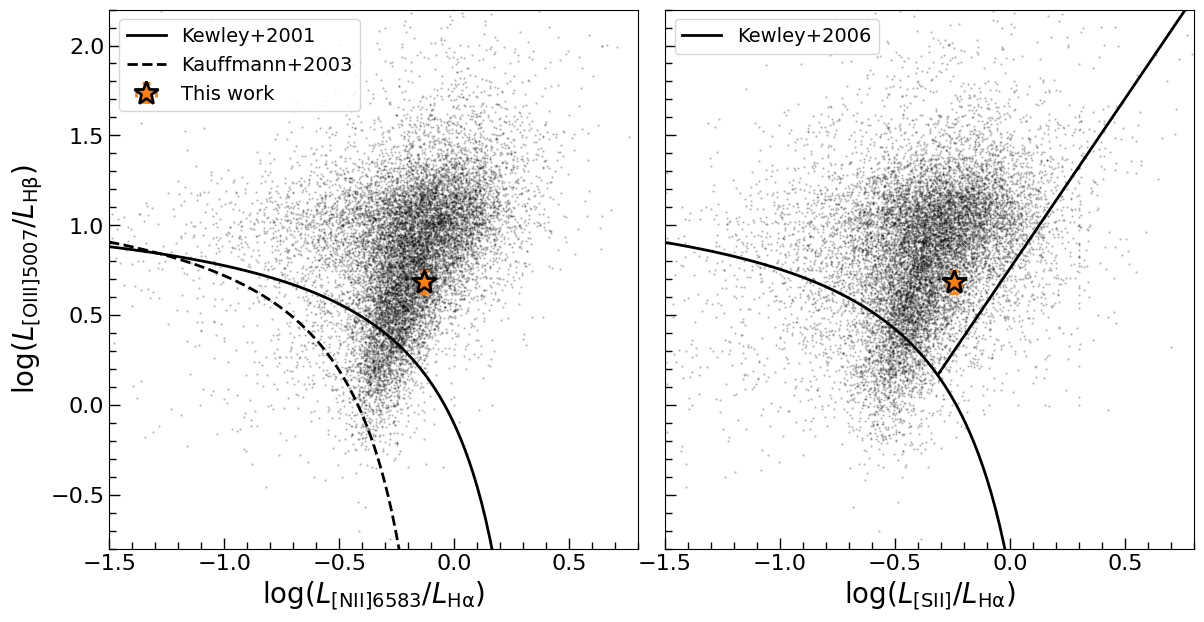

  log([N II] 6583 / H-alpha, narrow) = -0.133  (-0.152, -0.112)
  log([O III] 5007 / H-beta, narrow) = +0.682  (+0.624, +0.745)
  log([S II] 6716+6731 / H-alpha)    = -0.242  (-0.276, -0.212)
  the demarcations at this x: Kewley+2001 +0.18,  Kauffmann+2003 -2.03


In [25]:
# %% bpt
from astropy.table import Table
from astropy.io import fits
import warnings
from astropy.units import UnitsWarning

warnings.filterwarnings('ignore', category=UnitsWarning)
warnings.filterwarnings('ignore', category=fits.verify.VerifyWarning)
tb = Table.read(TABLE_DIR / 'Liu2019.fits', format='fits')

logLha_l19 = tb['logNHa']
logLhb_l19 = tb['logNHb']
logLn2_l19 = tb['log6583']
logLo3_l19 = tb['log5007']
logLs2_l19 = np.log10(10**tb['log6716'] + 10**tb['log6731'])

fig, axs = plt.subplots(1, 2, figsize=(14, 7), sharex=True, sharey=True)
fig.subplots_adjust(wspace=0.05)

# Narrow-line ratios: [N II], [S II] and [O III] are forbidden, i.e. they come from the
# narrow-line region and not from the broad one, so the Balmer denominator is the narrow
# component too. (See the note above this cell: dividing by the broad flux instead -- what
# the reference notebook's cell does -- dilutes both ratios and parks this Seyfert 1
# between the demarcation lines.)
ln2_ha = np.log10(flux_n2 / flux_nha)
lo3_hb = np.log10(flux_o3 / flux_nhb)
ls2_ha = np.log10(flux_s2 / flux_nha)

ax = axs[0]
x_t = np.median(ln2_ha)
y_t = np.median(lo3_hb)
x_t_e = np.percentile(ln2_ha, [16, 84])
y_t_e = np.percentile(lo3_hb, [16, 84])
ax.errorbar(x_t, y_t, xerr=[[x_t - x_t_e[0]], [x_t_e[1] - x_t]], yerr=[[y_t - y_t_e[0]], [y_t_e[1] - y_t]],
            ms=18, marker='*', ls='none', color='C1', mec='k', mew=2, label='This work', zorder=5, capsize=3)

x = logLn2_l19 - logLha_l19
y = logLo3_l19 - logLhb_l19
fltr = ((x > -10) & (x < 10)) & ((y > -10) & (y < 10))
ax.plot(x[fltr], y[fltr], ms=1, marker='.', ls='none', color='k', alpha=0.3)

ax.set_xlabel(r'$\log (L_{\rm [NII]6583}/L_{\rm H\alpha})$', fontsize=20)
ax.set_ylabel(r'$\log (L_{\rm [OIII]5007}/L_{\rm H\beta})$', fontsize=20)
ax.set_xlim(-1.5, 0.8)
ax.set_ylim(-0.8, 2.2)
ax.minorticks_on()

ax = axs[1]
x2_t = np.median(ls2_ha)
x2_t_e = np.percentile(ls2_ha, [16, 84])
ax.errorbar(x2_t, y_t, xerr=[[x2_t - x2_t_e[0]], [x2_t_e[1] - x2_t]], yerr=[[y_t - y_t_e[0]], [y_t_e[1] - y_t]],
            ms=18, marker='*', ls='none', color='C1', mec='k', mew=2, zorder=5, capsize=3)

x = logLs2_l19 - logLha_l19
fltr = ((x > -10) & (x < 10)) & ((y > -10) & (y < 10))
ax.plot(x[fltr], y[fltr], ms=1, marker='.', ls='none', color='k', alpha=0.3)
ax.set_xlabel(r'$\log (L_{\rm [SII]}/L_{\rm H\alpha})$', fontsize=20)
ax.minorticks_on()

# Demarcation lines; Kewley et al. (2001, 2006), Kauffmann et al. (2003)
x1 = np.linspace(-1.5, 0.3, 100)
y1 = 0.61 / (x1 - 0.47) + 1.19
axs[0].plot(x1, y1, ls='-', color='k', lw=2, label='Kewley+2001')

x2 = np.linspace(-1.5, 0.0, 100)
y2 = 0.61 / (x2 - 0.05) + 1.3
axs[0].plot(x2, y2, ls='--', color='k', lw=2, label='Kauffmann+2003')

x3 = np.linspace(-1.5, 0.3, 100)
y3 = 0.72 / (x3 - 0.32) + 1.3
axs[1].plot(x3, y3, ls='-', color='k', lw=2, label='Kewley+2006')

x4 = np.linspace(-0.31, 0.8, 100)
y4 = 1.89 * x4 + 0.76
axs[1].plot(x4, y4, ls='-', color='k', lw=2)

axs[0].legend(loc='upper left', fontsize=14)
axs[1].legend(loc='upper left', fontsize=14)
fig.savefig(OUTPUT_DIR / 'sdss0006_bpt.png', dpi=140, bbox_inches='tight')
plt.show()

print(f"  log([N II] 6583 / H-alpha, narrow) = {x_t:+.3f}  ({x_t_e[0]:+.3f}, {x_t_e[1]:+.3f})")
print(f"  log([O III] 5007 / H-beta, narrow) = {y_t:+.3f}  ({y_t_e[0]:+.3f}, {y_t_e[1]:+.3f})")
print(f"  log([S II] 6716+6731 / H-alpha)    = {x2_t:+.3f}  ({x2_t_e[0]:+.3f}, {x2_t_e[1]:+.3f})")
print(f"  the demarcations at this x: Kewley+2001 {0.61 / (x_t - 0.47) + 1.19:+.2f},"
      f"  Kauffmann+2003 {0.61 / (x_t - 0.05) + 1.3:+.2f}")

### Check the black hole mass
* Read this [Annual Review for Astronomy and Astrophysics paper](https://scixplorer.org/abs/2013ARA&A..51..511K/abstract) to learn more

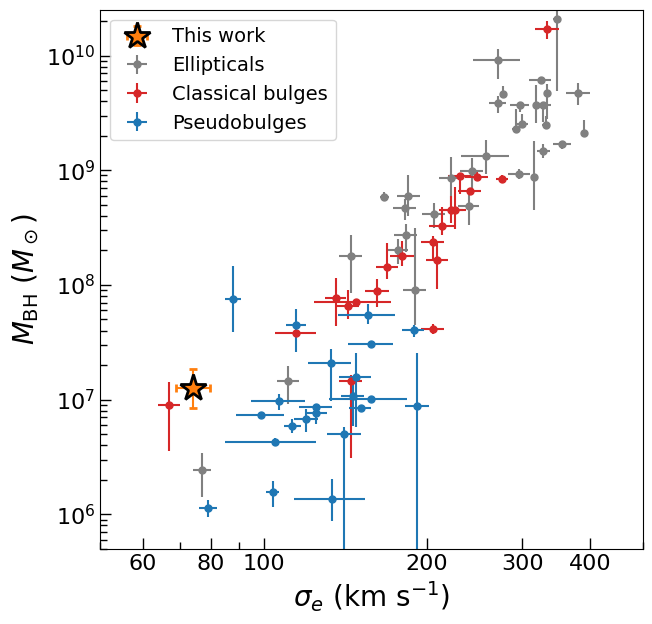

  sigma_* = 74.2 (-5.3/+5.6) km/s
  log M_BH = 7.10 (-0.17/+0.17)


In [26]:
# %% mbh_sigma
# Table 2 and 3 of Kormendy & Ho (2013, ARA&A, 51, 511)
tb2 = Table.read(TABLE_DIR / 'tab2.ipac', format='ascii.ipac')
tb3 = Table.read(TABLE_DIR / 'tab3.ipac', format='ascii.ipac')

Mbh_k13 = np.concatenate([tb2['Mbh'], tb3['Mbh']])
lMbh_k13 = np.concatenate([tb2['lMbh'], tb3['lMbh']])
uMbh_k13 = np.concatenate([tb2['uMbh'], tb3['uMbh']])
sigma_k13 = np.ma.concatenate([tb2['sigma'], tb3['sigma']])
esigma_k13 = np.ma.concatenate([tb2['esigma'], tb3['esigma']])
flag = np.concatenate([tb2['flag'], tb3['flag']])
flag_ell = np.concatenate([np.ones_like(tb2['Mbh']), np.zeros_like(tb3['Mbh'])])  # 1 for elliptical, 0 for disk

fig, ax = plt.subplots(figsize=(7, 7))

logMbh_med = float(np.median(logMbh))
logMbh_e = np.percentile(logMbh, [16, 84])
ax.errorbar(sigma_star, 10**logMbh_med,
            xerr=[[sigma_star - sigma_star_lo], [sigma_star_hi - sigma_star]],
            yerr=[[10**logMbh_med - 10**logMbh_e[0]], [10**logMbh_e[1] - 10**logMbh_med]],
            ms=20, marker='*', ls='none', color='C1', mec='k', mew=2, label='This work',
            zorder=5, capsize=3)

fltr = (flag == 1) & (flag_ell == 1)
ax.errorbar(sigma_k13[fltr], Mbh_k13[fltr], xerr=esigma_k13[fltr], yerr=[Mbh_k13[fltr] - lMbh_k13[fltr], uMbh_k13[fltr] - Mbh_k13[fltr]],
            fmt='o', ms=5, color='gray', label='Ellipticals')
fltr = (flag == 1) & (flag_ell == 0)
ax.errorbar(sigma_k13[fltr], Mbh_k13[fltr], xerr=esigma_k13[fltr], yerr=[Mbh_k13[fltr] - lMbh_k13[fltr], uMbh_k13[fltr] - Mbh_k13[fltr]],
            fmt='o', ms=5, color='C3', label='Classical bulges')
fltr = (flag == 3)
ax.errorbar(sigma_k13[fltr], Mbh_k13[fltr], xerr=esigma_k13[fltr], yerr=[Mbh_k13[fltr] - lMbh_k13[fltr], uMbh_k13[fltr] - Mbh_k13[fltr]],
            fmt='o', ms=5, color='C0', label='Pseudobulges')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim([50, 500])
ax.set_ylim([5e5, 2.5e10])

ax.set_xticks([60, 80, 100, 200, 300, 400])
ax.set_xticklabels([60, 80, 100, 200, 300, 400])
ax.set_xlabel(r'$\sigma_e\ (\rm km\ s^{-1})$', fontsize=20)
ax.set_ylabel(r'$M_{\rm BH}\ (M_\odot)$', fontsize=20)
ax.legend(loc='upper left', fontsize=14)
fig.savefig(OUTPUT_DIR / 'sdss0006_mbh_sigma.png', dpi=140, bbox_inches='tight')
plt.show()

print(f"  sigma_* = {sigma_star:.1f} (-{sigma_star - sigma_star_lo:.1f}/+{sigma_star_hi - sigma_star:.1f}) km/s")
print(f"  log M_BH = {logMbh_med:.2f} (-{logMbh_med - logMbh_e[0]:.2f}/+{logMbh_e[1] - logMbh_med:.2f})")

## Saving the fit

A nested-sampling run is the expensive part, so the last stage is written to a FITS file that
`galspec.jnesty_fit_io.load_jnesty_fit_from_fits` reads back into a `JNesty_Fit`: the samples
and their weights, the evidence, the parameter names and bounds, the priors, the model
description and the spectrum that was fitted. Everything in this notebook can then be redone
without resampling.

In [27]:
# %% save
fits_path = OUTPUT_DIR / 'sdss0006_jax_fit.fits'
save_jnesty_fit_to_fits(fit_hb, fits_path)
print(f"  wrote {fits_path}  ({fits_path.stat().st_size / 1e6:.0f} MB)")
print(f"  read it back with load_jnesty_fit_from_fits({str(fits_path)!r})")
fit_hb.release_device_buffers()

JNesty_Fit object saved to /home/shangguan/Softwares/my_modules/GalSpec/example/output/sdss0006_jax_fit.fits
  wrote /home/shangguan/Softwares/my_modules/GalSpec/example/output/sdss0006_jax_fit.fits  (39 MB)
  read it back with load_jnesty_fit_from_fits('/home/shangguan/Softwares/my_modules/GalSpec/example/output/sdss0006_jax_fit.fits')


## What this does and does not show

* **The continuum decomposition is not unique.** Five stellar templates plus a power law fit
  the same windows about equally well in a whole family of proportions; the medians above are
  one representative. $\lambda L_\lambda(5100)$ survives it -- every decomposition carries the
  same flux there, to $\pm 12\%$ in one run and $1.9$-$2.3 \times 10^{42}$ erg/s across runs --
  and $\sigma_*$ does not. This is a property of the method, not of the sampler: a
  least-squares fit hides the same degeneracy behind a single point.
* **The stages are fitted separately.** Each stage samples its own posterior, and the BH mass
  pairs the continuum luminosity with the Hβ width from two independent runs. A joint fit over
  the whole spectrum would be the clean way to carry every correlation; the staged procedure is
  what the reference notebook does, and it is what is reproduced here.
* **The narrow lines share one measured profile.** The template comes from [S II] and is
  applied to Hα, Hβ, [O III] and [N II]; if the Balmer narrow lines are broader than [S II] --
  they often are -- those lines are under-fitted, and the residual panels say so.
* **The [O III] wing is detected, not measured.** Its amplitude is $0.38\,(-0.22/+0.66)$ and
  its width $510\,(-250/+610)$ km/s: something broad sits under 5007, and neither its strength
  nor its shape is pinned down. Read it as "a broad base is present", not as a velocity of an
  outflow.
* **The posterior is broader than one run suggests, where the model is degenerate.** Two
  JNesty configurations of the continuum stage -- same data, same priors, different bounding --
  returned evidences 1.3 nats apart and $\sigma_*$ values of $74$ and $86$ km/s whose 68%
  intervals do not even overlap. Both are approximations of one posterior that neither run
  fully mapped: the star-template/power-law split is a direction the data hardly constrain,
  and the sampler can occupy different parts of it. This is worth checking on any object
  before believing a $\sigma_*$ -- run the stage twice and look at the spread.
* **The H$_\alpha$ stage was checked against another sampler.** With the window and the
  template held fixed, two JNesty runs give $\log Z = -460.9$ and $-461.4$, both with
  $\sigma(\mathrm{bH\alpha}) = 1346$ km/s; `dynesty`, sampling the astropy twin of the same
  model on the CPU, gives $-461.8 \pm 0.2$ and $\sigma = 1350$ km/s with a 68% interval of
  $[1212, 1497]$. That is the check that the GPU path is not merely self-consistent.
* **No instrumental resolution.** The [S II] profile includes the SDSS line-spread function
  (about 2.4 A in FWHM, i.e. 107 km/s at 6 700 A). Subtract it in quadrature if you need the
  gas kinematics alone -- the reference notebook does the same thing, i.e. nothing.